<a href="https://colab.research.google.com/github/BraianRom/grupo10-data-science/blob/main/notebooks/fase3_parte1_diseno_experimento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fase 3 — Parte 1: Diseño del experimento

**Grupo 10 — Ciencia de Datos**

Esta parte cubre las actividades 1 a 4 del punto 7.1 de la consigna y deja preparado lo que necesitan
las Partes 2 (modelado) y 3 (evaluación):

1. Definición de la tarea predictiva y de la variable objetivo.
2. Construcción del dataset de modelado (panel día × local × sección, con variables de calendario, clima y rezagos).
3. Partición cronológica entrenamiento / prueba, con semilla fija.
4. Líneas base triviales contra las que se compara todo modelo posterior.

Además se define la **función de métricas compartida**, para que las tres partes reporten exactamente lo mismo.

> **Regla que no se toca:** el conjunto de prueba se usa una sola vez, al final del proyecto (Parte 3).
> Ni la Parte 1 ni la Parte 2 ajustan nada mirando el test.

# 0. Preparación del entorno

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown
import json, warnings
warnings.filterwarnings('ignore')

try:
    import holidays
except ImportError:
    !pip install -q holidays
    import holidays

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

# Semilla única para todo el proyecto (la reutilizan las Partes 2 y 3)
SEMILLA = 42
np.random.seed(SEMILLA)
print('Entorno listo. Semilla =', SEMILLA)

Entorno listo. Semilla = 42


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Rutas. AJUSTAR si tenés la carpeta compartida montada en otro lugar.
RUTA_BASE     = "/content/drive/MyDrive/grupo10_data_science"
RUTA_DF_FINAL = f"{RUTA_BASE}/datos/df_final.parquet"
RUTA_SALIDA   = f"{RUTA_BASE}/fase3"   # acá se guardan los artefactos para las Partes 2 y 3

df_final = pd.read_parquet(RUTA_DF_FINAL)
print(f"df_final: {df_final.shape[0]:,} filas x {df_final.shape[1]} columnas")
print(f"Rango de fechas: {df_final['fecha_vta'].min().date()} a {df_final['fecha_vta'].max().date()}")
print(f"Fechas únicas: {df_final['fecha_vta'].nunique()}")

df_final: 9,447,662 filas x 17 columnas
Rango de fechas: 2021-01-02 a 2021-09-30
Fechas únicas: 271


# 1. Definición de la tarea predictiva

**Tarea:** regresión.

**Variable objetivo:** `cantidad` — unidades vendidas por día, local y sección comercial.

**Unidad de análisis:** día × local × sección. Se eligió este nivel y no otros por tres razones:

- A nivel de transacción individual, `cantidad` vale casi siempre 1 (el rango intercuartílico es 0 en la
  Fase 1): predecir esa variable no tiene contenido informativo.
- A nivel día × local quedan solo 540 observaciones, insuficientes para modelos basados en árboles.
- El nivel día × local × sección es el que corresponde al **objetivo específico 5** de la propuesta:
  "desarrollar un modelo predictivo de demanda diaria por categoría a un día (t+1) incorporando el
  pronóstico del tiempo y evaluar si reduce el error respecto a un modelo base".

**Horizonte:** un día (t+1). El modelo predice la demanda del día siguiente usando información disponible
hasta el día anterior, más el pronóstico de temperatura del día a predecir.

**Vínculo con las fases anteriores:** la Fase 2 (H3) encontró que la pendiente de la temperatura difiere
entre secciones (entre −2.2 % y +1.3 % por °C), y que el calendario domina sobre el clima en las ventas
totales (H2, H4). El modelo predictivo debe poder confirmar o desmentir ese orden de importancia: si la
temperatura resulta poco relevante frente a las variables de calendario, será coherente con lo hallado.

# 2. Construcción del dataset de modelado

## 2.1 Selección de secciones

Se conservan las secciones con al menos 100.000 registros transaccionales, el mismo criterio usado en la
Fase 2 (H3). Las secciones de muy bajo volumen generan series casi vacías, en las que la métrica queda
dominada por el ruido.

In [4]:
MIN_REGISTROS_SECCION = 100_000

conteo_secciones = df_final['desc_secciones'].value_counts()
secciones = sorted(conteo_secciones[conteo_secciones >= MIN_REGISTROS_SECCION].index.tolist())
locales   = sorted(df_final['local'].unique().tolist())

print(f"Secciones conservadas ({len(secciones)}): {secciones}")
print(f"Secciones descartadas ({(conteo_secciones < MIN_REGISTROS_SECCION).sum()}): "
      f"{sorted(conteo_secciones[conteo_secciones < MIN_REGISTROS_SECCION].index.tolist())}")
print(f"Locales: {locales}")
print(f"Cobertura: {conteo_secciones[secciones].sum() / len(df_final) * 100:.2f}% de los registros originales")

Secciones conservadas (9): ['Almacen', 'Bazar', 'Bebidas', 'Belleza y Salud', 'Insumos', 'Limpieza', 'Perecederos ', 'Produccion', 'Tienda']
Secciones descartadas (3): ['Hogar', 'Perecederos Terceros', 'Servicios ']
Locales: ['Local X', 'Local Y']
Cobertura: 99.93% de los registros originales


## 2.2 Agregación a panel día × local × sección

Se suma la cantidad vendida por cada combinación de día, local y sección. La temperatura se calcula
aparte, a nivel día × local, porque es la misma para todas las secciones de un mismo local y día.

In [5]:
# Cantidad vendida por día, local y sección
panel = (
    df_final[df_final['desc_secciones'].isin(secciones)]
    .groupby(['fecha_vta', 'local', 'desc_secciones'], observed=True)['cantidad']
    .sum()
    .reset_index()
)

# Temperatura diaria por local (idéntica para todas las secciones de ese local y día)
temp_diaria = (
    df_final.groupby(['fecha_vta', 'local'], observed=True)['temperatura']
    .mean()
    .reset_index()
)

print(f"Celdas observadas en el panel: {len(panel):,}")
panel.head()

Celdas observadas en el panel: 4,860


,fecha_vta,local,desc_secciones,cantidad
0,2021-01-02,Local X,Almacen,8262.385
1,2021-01-02,Local X,Bazar,1999.945
2,2021-01-02,Local X,Bebidas,1786.000
3,2021-01-02,Local X,Belleza y Salud,1549.000
4,2021-01-02,Local X,Insumos,291.000


## 2.3 Grilla completa de fechas

El panel se reindexa sobre **todos los días del calendario** entre la primera y la última fecha, para que
los rezagos (`lag_7`) signifiquen "siete días atrás" y no "siete filas atrás". Sin esto, un día faltante
correría todos los rezagos posteriores y el modelo quedaría mal especificado sin que nadie lo note.

Las celdas sin ventas quedan como `NaN` y **no se imputan con cero**: un día sin registros es un día en que
el local no operó, no un día de cero ventas. Esas filas se excluyen del entrenamiento y de la evaluación,
pero se conservan en la grilla para que los rezagos se calculen bien.

In [6]:
fechas_calendario = pd.date_range(panel['fecha_vta'].min(), panel['fecha_vta'].max(), freq='D')

grilla = pd.MultiIndex.from_product(
    [fechas_calendario, locales, secciones],
    names=['fecha_vta', 'local', 'desc_secciones']
).to_frame(index=False)

panel = grilla.merge(panel, on=['fecha_vta', 'local', 'desc_secciones'], how='left')
panel = panel.merge(temp_diaria, on=['fecha_vta', 'local'], how='left')

n_celdas   = len(panel)
n_faltante = int(panel['cantidad'].isna().sum())

print(f"Días de calendario: {len(fechas_calendario)}  ({fechas_calendario.min().date()} a {fechas_calendario.max().date()})")
print(f"Celdas en la grilla completa: {n_celdas:,}")
print(f"Celdas sin ventas (NaN, no imputadas): {n_faltante:,} ({n_faltante / n_celdas * 100:.2f}%)")

dias_sin_ventas = (
    panel.groupby(['fecha_vta', 'local'], observed=True)['cantidad']
    .apply(lambda s: s.isna().all())
)
dias_sin_ventas = dias_sin_ventas[dias_sin_ventas].reset_index()
if len(dias_sin_ventas):
    print("\nDías sin ninguna venta registrada (local no operó):")
    display(dias_sin_ventas[['fecha_vta', 'local']])

Días de calendario: 272  (2021-01-02 a 2021-09-30)
Celdas en la grilla completa: 4,896
Celdas sin ventas (NaN, no imputadas): 36 (0.74%)

Días sin ninguna venta registrada (local no operó):


,fecha_vta,local
0,2021-04-02,Local X
1,2021-04-02,Local Y
2,2021-06-15,Local X
3,2021-09-11,Local X


## 2.4 Variables de calendario

Se recalculan desde la fecha —y no se toman de `df_final`— porque las filas agregadas en la grilla no
tienen transacciones de las cuales heredarlas.

In [7]:
panel['dia_semana']       = panel['fecha_vta'].dt.dayofweek          # 0 = lunes
panel['es_fin_de_semana'] = panel['dia_semana'].isin([5, 6]).astype(int)
panel['mes']              = panel['fecha_vta'].dt.month
panel['dia_del_mes']      = panel['fecha_vta'].dt.day

feriados_py = holidays.Paraguay(years=sorted(panel['fecha_vta'].dt.year.unique().tolist()))
panel['es_feriado'] = panel['fecha_vta'].dt.date.isin(feriados_py).astype(int)

# Quincena y fin de mes: en retail el cobro de haberes mueve la demanda
panel['es_quincena']   = panel['dia_del_mes'].isin([15, 16]).astype(int)
panel['es_fin_de_mes'] = (panel['dia_del_mes'] >= 28).astype(int)

print(f"Feriados en el período: {panel.loc[panel['es_feriado'] == 1, 'fecha_vta'].nunique()}")
panel[['fecha_vta', 'dia_semana', 'es_fin_de_semana', 'mes', 'es_feriado', 'es_quincena', 'es_fin_de_mes']].head()

Feriados en el período: 10


,fecha_vta,dia_semana,es_fin_de_semana,mes,es_feriado,es_quincena,es_fin_de_mes
0,2021-01-02,5,1,1,0,0,0
1,2021-01-02,5,1,1,0,0,0
2,2021-01-02,5,1,1,0,0,0
3,2021-01-02,5,1,1,0,0,0
4,2021-01-02,5,1,1,0,0,0


## 2.5 Rezagos y medias móviles

Son las variables más predictivas en una serie de demanda: lo que se vendió ayer y lo que se vendió el
mismo día de la semana pasada.

**Cuidado con la fuga de información:** todos los rezagos se calculan dentro de cada serie
(local × sección) y desplazados hacia atrás, de modo que una fila nunca contiene información de su propio
día ni de días posteriores. La media móvil se calcula sobre la serie ya desplazada, por el mismo motivo.

In [8]:
panel = panel.sort_values(['local', 'desc_secciones', 'fecha_vta']).reset_index(drop=True)
grupos = panel.groupby(['local', 'desc_secciones'], observed=True)['cantidad']

panel['lag_1']  = grupos.shift(1)    # día anterior
panel['lag_7']  = grupos.shift(7)    # mismo día de la semana anterior
panel['lag_14'] = grupos.shift(14)

# Media móvil de 7 días sobre la serie desplazada: nunca incluye el día que se predice
panel['media_movil_7']  = grupos.transform(lambda s: s.shift(1).rolling(7,  min_periods=7).mean())
panel['media_movil_28'] = grupos.transform(lambda s: s.shift(1).rolling(28, min_periods=28).mean())

print("Verificación de no-fuga: la correlación entre 'cantidad' y cada rezago debe ser < 1")
for col in ['lag_1', 'lag_7', 'lag_14', 'media_movil_7', 'media_movil_28']:
    sub = panel[['cantidad', col]].dropna()
    print(f"  {col:16s} corr = {sub['cantidad'].corr(sub[col]):.4f}   (n = {len(sub):,})")

Verificación de no-fuga: la correlación entre 'cantidad' y cada rezago debe ser < 1
  lag_1            corr = 0.9244   (n = 4,806)
  lag_7            corr = 0.9580   (n = 4,698)
  lag_14           corr = 0.9618   (n = 4,572)
  media_movil_7    corr = 0.9318   (n = 4,482)
  media_movil_28   corr = 0.9303   (n = 3,429)


## 2.6 Supuesto sobre la temperatura

La temperatura del día `t` se usa como variable predictora de las ventas del día `t`. Esto supone que al
momento de predecir se dispone del **pronóstico** de ese día, que es exactamente el escenario de uso
planteado en la propuesta ("incorporando el pronóstico del tiempo").

No es una fuga de información respecto del objetivo —la temperatura no se deriva de las ventas—, pero sí
es un supuesto optimista: en la práctica el pronóstico tiene error propio, y el desempeño real sería algo
peor que el medido acá. Queda registrado como limitación para la conclusión de la Fase 3.

In [9]:
# Conjunto de variables predictoras que usarán las Partes 2 y 3
VARIABLES_NUMERICAS = ['temperatura', 'lag_1', 'lag_7', 'lag_14', 'media_movil_7', 'media_movil_28']
VARIABLES_CALENDARIO = ['dia_semana', 'es_fin_de_semana', 'mes', 'es_feriado', 'es_quincena', 'es_fin_de_mes']
VARIABLES_CATEGORICAS = ['local', 'desc_secciones']
OBJETIVO = 'cantidad'

PREDICTORAS = VARIABLES_NUMERICAS + VARIABLES_CALENDARIO + VARIABLES_CATEGORICAS

print(f"Objetivo: {OBJETIVO}")
print(f"Predictoras ({len(PREDICTORAS)}): {PREDICTORAS}")

Objetivo: cantidad
Predictoras (14): ['temperatura', 'lag_1', 'lag_7', 'lag_14', 'media_movil_7', 'media_movil_28', 'dia_semana', 'es_fin_de_semana', 'mes', 'es_feriado', 'es_quincena', 'es_fin_de_mes', 'local', 'desc_secciones']


## 2.7 Filas utilizables

Se descartan las filas sin objetivo (días en que el local no operó) y las que no tienen todos los rezagos
calculados (los primeros 28 días de cada serie). Las filas descartadas por rezagos son inevitables: una
serie no puede aportar su media móvil de 28 días antes de tener 28 días de historia.

In [10]:
antes = len(panel)
sin_objetivo = int(panel[OBJETIVO].isna().sum())

panel_modelado = panel.dropna(subset=[OBJETIVO] + VARIABLES_NUMERICAS).copy()

print(f"Celdas en la grilla completa:          {antes:,}")
print(f"  - descartadas por falta de objetivo: {sin_objetivo:,}")
print(f"  - descartadas por rezagos faltantes: {antes - sin_objetivo - len(panel_modelado):,}")
print(f"Filas utilizables para modelar:        {len(panel_modelado):,}")
print(f"\nRango de fechas utilizable: {panel_modelado['fecha_vta'].min().date()} a {panel_modelado['fecha_vta'].max().date()}")
print(f"Días distintos: {panel_modelado['fecha_vta'].nunique()}")

Celdas en la grilla completa:          4,896
  - descartadas por falta de objetivo: 36
  - descartadas por rezagos faltantes: 1,431
Filas utilizables para modelar:        3,429

Rango de fechas utilizable: 2021-01-30 a 2021-09-30
Días distintos: 215


# 3. Partición cronológica

La consigna es explícita: *"si hay componente temporal, la partición debe ser cronológica y no aleatoria:
entrenar con el futuro para predecir el pasado es un error grave"*.

Se reserva el **último 20 % de los días** como conjunto de prueba. El corte es por fecha, no por fila: todas
las series (local × sección) se cortan el mismo día, de modo que ninguna observación de entrenamiento es
posterior a una de prueba.

In [11]:
PROPORCION_TEST = 0.20

fechas_ordenadas = np.sort(panel_modelado['fecha_vta'].unique())
indice_corte = int(len(fechas_ordenadas) * (1 - PROPORCION_TEST))
FECHA_CORTE = pd.Timestamp(fechas_ordenadas[indice_corte])

train = panel_modelado[panel_modelado['fecha_vta'] <  FECHA_CORTE].copy()
test  = panel_modelado[panel_modelado['fecha_vta'] >= FECHA_CORTE].copy()

print(f"Fecha de corte: {FECHA_CORTE.date()}")
print(f"\nEntrenamiento: {len(train):,} filas | {train['fecha_vta'].min().date()} a {train['fecha_vta'].max().date()} | {train['fecha_vta'].nunique()} días")
print(f"Prueba:        {len(test):,} filas | {test['fecha_vta'].min().date()} a {test['fecha_vta'].max().date()} | {test['fecha_vta'].nunique()} días")
print(f"\nProporción de prueba: {len(test) / len(panel_modelado) * 100:.1f}% de las filas")

Fecha de corte: 2021-08-19

Entrenamiento: 2,835 filas | 2021-01-30 a 2021-08-18 | 172 días
Prueba:        594 filas | 2021-08-19 a 2021-09-30 | 43 días

Proporción de prueba: 17.3% de las filas


In [12]:
# --- Verificación de la partición (no debe fallar ninguna) ---
assert train['fecha_vta'].max() < test['fecha_vta'].min(), "Hay solapamiento temporal entre train y test"
assert len(train) + len(test) == len(panel_modelado), "Se perdieron filas en la partición"
assert set(train.index).isdisjoint(set(test.index)), "Hay filas compartidas entre train y test"

print("Verificación de la partición: correcta")
print(f"  Última fecha de entrenamiento: {train['fecha_vta'].max().date()}")
print(f"  Primera fecha de prueba:       {test['fecha_vta'].min().date()}")
print(f"  Separación: {(test['fecha_vta'].min() - train['fecha_vta'].max()).days} día(s)")

# Cobertura: todas las combinaciones local x sección deben aparecer en ambos conjuntos
comb_train = set(map(tuple, train[['local', 'desc_secciones']].drop_duplicates().values))
comb_test  = set(map(tuple, test[['local', 'desc_secciones']].drop_duplicates().values))
print(f"\nCombinaciones local x sección en train: {len(comb_train)} | en test: {len(comb_test)}")
print(f"Combinaciones presentes en test pero no en train: {comb_test - comb_train or 'ninguna'}")

Verificación de la partición: correcta
  Última fecha de entrenamiento: 2021-08-18
  Primera fecha de prueba:       2021-08-19
  Separación: 1 día(s)

Combinaciones local x sección en train: 18 | en test: 18
Combinaciones presentes en test pero no en train: ninguna


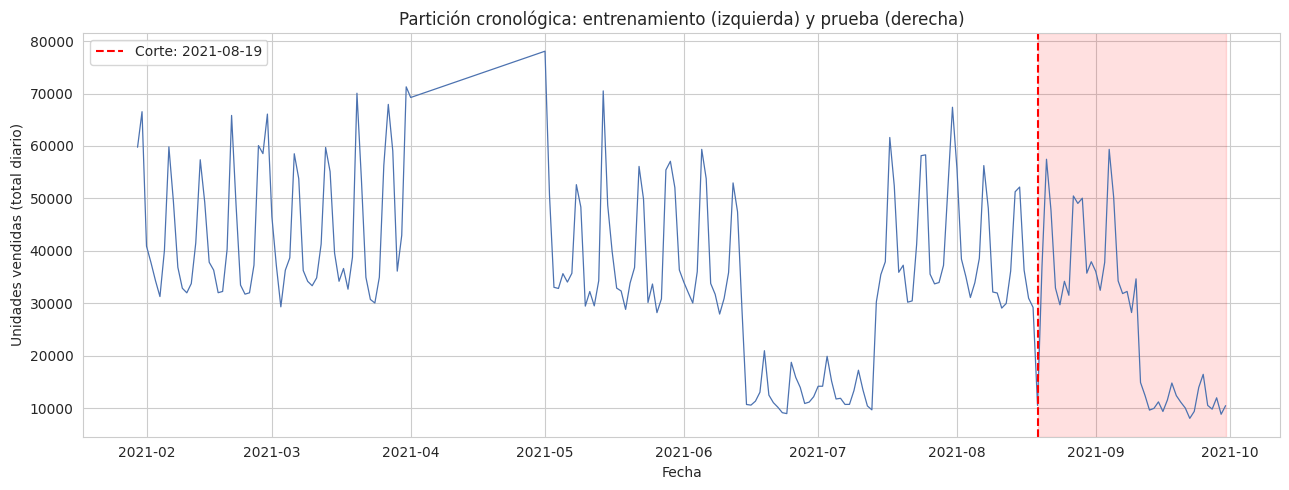

In [13]:
# Visualización de la partición sobre la serie total diaria
serie_total = panel_modelado.groupby('fecha_vta', observed=True)[OBJETIVO].sum()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(serie_total.index, serie_total.values, linewidth=0.9, color='#4C72B0')
ax.axvline(FECHA_CORTE, color='red', linestyle='--', linewidth=1.5,
           label=f'Corte: {FECHA_CORTE.date()}')
ax.axvspan(FECHA_CORTE, serie_total.index.max(), alpha=0.12, color='red')
ax.set_title('Partición cronológica: entrenamiento (izquierda) y prueba (derecha)')
ax.set_xlabel('Fecha')
ax.set_ylabel('Unidades vendidas (total diario)')
ax.legend()
plt.tight_layout()
plt.show()

# 4. Función de métricas compartida

Las tres partes reportan exactamente estas métricas, calculadas con esta misma función, para que los
resultados sean comparables entre sí y contra la línea base.

- **RMSE**: penaliza más los errores grandes; está en unidades vendidas.
- **MAE**: error absoluto promedio, en unidades vendidas; más fácil de comunicar.
- **MAPE**: error porcentual; se calcula **solo sobre las filas con objetivo distinto de cero**, y se
  informa cuántas filas se excluyeron. La consigna lo pide "cuando la escala lo permita".
- **R²**: proporción de varianza explicada.

In [14]:
def metricas(y_true, y_pred, nombre='modelo'):
    """Métricas de regresión en un formato único para todo el proyecto.

    MAPE se calcula solo donde y_true != 0 y se informa cuántas filas quedaron excluidas.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    valido = ~(np.isnan(y_true) | np.isnan(y_pred))
    y_true, y_pred = y_true[valido], y_pred[valido]

    no_cero = y_true != 0
    mape = float(np.mean(np.abs((y_true[no_cero] - y_pred[no_cero]) / y_true[no_cero])) * 100) if no_cero.any() else np.nan

    return {
        'modelo': nombre,
        'n': int(len(y_true)),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'MAPE_%': mape,
        'R2': float(r2_score(y_true, y_pred)),
        'filas_excluidas_MAPE': int((~no_cero).sum()),
    }


def tabla_metricas(lista_resultados):
    """Arma la tabla comparativa a partir de varias salidas de metricas()."""
    return pd.DataFrame(lista_resultados).set_index('modelo').round(4)


# Prueba rápida de la función
_demo = metricas([10, 20, 30, 0], [12, 18, 33, 1], 'demo')
print(_demo)

{'modelo': 'demo', 'n': 4, 'RMSE': 2.1213203435596424, 'MAE': 2.0, 'MAPE_%': 13.333333333333334, 'R2': 0.964, 'filas_excluidas_MAPE': 1}


# 5. Líneas base

La consigna pide un modelo trivial contra el cual justificar la existencia de cualquier modelo posterior.
Se establecen **dos**, porque miden cosas distintas:

1. **Media por grupo** — predecir siempre el promedio histórico de esa combinación local × sección.
   Es la línea base mínima: un modelo que no la supere no aprendió nada.
2. **Ingenua estacional (lag-7)** — predecir lo mismo que se vendió el mismo día de la semana anterior.
   En series con estacionalidad semanal fuerte —como la demanda en retail— suele ser una línea base dura
   de batir, y es la comparación honesta.

Ambas se calculan **con datos de entrenamiento únicamente** y se evalúan sobre prueba.

In [15]:
# --- Línea base 1: media por local x sección (calculada solo con entrenamiento) ---
medias_grupo = train.groupby(['local', 'desc_secciones'], observed=True)[OBJETIVO].mean()
media_global = train[OBJETIVO].mean()

pred_media = (
    test.set_index(['local', 'desc_secciones']).index.map(medias_grupo).to_numpy(dtype=float)
)
pred_media = np.where(np.isnan(pred_media), media_global, pred_media)

# --- Línea base 2: ingenua estacional (mismo día de la semana anterior) ---
pred_naive = test['lag_7'].to_numpy(dtype=float)

base_media = metricas(test[OBJETIVO], pred_media, 'Base 1 — media por local x sección')
base_naive = metricas(test[OBJETIVO], pred_naive, 'Base 2 — ingenua estacional (lag-7)')

tabla_base = tabla_metricas([base_media, base_naive])
display(tabla_base)

,n,RMSE,MAE,MAPE_%,R2,filas_excluidas_MAPE
modelo,,,,,,
Base 1 — media por local x sección,594,1077.2432,603.7891,67.4026,0.7810,0
Base 2 — ingenua estacional (lag-7),594,700.6424,317.9784,39.4546,0.9073,0


In [16]:
# Las mismas líneas base medidas sobre entrenamiento, para que la Parte 3 pueda discutir la brecha
pred_media_tr = train.set_index(['local', 'desc_secciones']).index.map(medias_grupo).to_numpy(dtype=float)
pred_media_tr = np.where(np.isnan(pred_media_tr), media_global, pred_media_tr)
pred_naive_tr = train['lag_7'].to_numpy(dtype=float)

tabla_base_train = tabla_metricas([
    metricas(train[OBJETIVO], pred_media_tr, 'Base 1 — media (entrenamiento)'),
    metricas(train[OBJETIVO], pred_naive_tr, 'Base 2 — lag-7 (entrenamiento)'),
])
display(tabla_base_train)

,n,RMSE,MAE,MAPE_%,R2,filas_excluidas_MAPE
modelo,,,,,,
Base 1 — media (entrenamiento),2835,1167.3761,630.1236,51.4892,0.8525,0
Base 2 — lag-7 (entrenamiento),2835,850.8450,384.7753,22.6454,0.9216,0


In [17]:
# --- Lectura de las líneas base ---
mejor = tabla_base['RMSE'].idxmin()
rmse_mejor = tabla_base.loc[mejor, 'RMSE']
mae_mejor  = tabla_base.loc[mejor, 'MAE']
venta_media_test = float(test[OBJETIVO].mean())

display(Markdown(f'''
**Línea base a superar:** `{mejor}`, con **RMSE = {rmse_mejor:.2f}** y **MAE = {mae_mejor:.2f}** unidades
sobre el conjunto de prueba.

Como referencia, la venta media por celda (día × local × sección) en el conjunto de prueba es de
**{venta_media_test:.1f} unidades**, de modo que el MAE de la línea base equivale a un
**{mae_mejor / venta_media_test * 100:.1f}%** de la venta media.

Todo modelo de la Parte 2 debe compararse contra este valor. Un modelo que no lo supere no justifica su
existencia, y así debe reportarse: la consigna valora reconocerlo más que disimularlo.
'''))


**Línea base a superar:** `Base 2 — ingenua estacional (lag-7)`, con **RMSE = 700.64** y **MAE = 317.98** unidades
sobre el conjunto de prueba.

Como referencia, la venta media por celda (día × local × sección) en el conjunto de prueba es de
**1866.5 unidades**, de modo que el MAE de la línea base equivale a un
**17.0%** de la venta media.

Todo modelo de la Parte 2 debe compararse contra este valor. Un modelo que no lo supere no justifica su
existencia, y así debe reportarse: la consigna valora reconocerlo más que disimularlo.


# 6. Artefactos para las Partes 2 y 3

Se guardan en `fase3/` del Drive compartido:

| Archivo | Para qué sirve | Quién lo usa |
|---|---|---|
| `panel_modelado.parquet` | Dataset completo ya construido (train + test juntos, con la columna `particion`) | Partes 2 y 3 |
| `config_fase3.json` | Fecha de corte, semilla, listas de variables y métricas de la línea base | Partes 2 y 3 |
| `metricas_fase3.py` | Función de métricas compartida, para copiar a `/src` del repositorio | Partes 2 y 3 |

La Parte 2 carga el panel, filtra `particion == 'train'` y trabaja solo con eso. **No toca `test`.**

In [18]:
import os
os.makedirs(RUTA_SALIDA, exist_ok=True)

# Panel con la partición marcada
panel_export = panel_modelado.copy()
panel_export['particion'] = np.where(panel_export['fecha_vta'] < FECHA_CORTE, 'train', 'test')
panel_export.to_parquet(f"{RUTA_SALIDA}/panel_modelado.parquet", index=False)

config = {
    'semilla': SEMILLA,
    'objetivo': OBJETIVO,
    'unidad_de_analisis': 'fecha_vta x local x desc_secciones',
    'fecha_corte': str(FECHA_CORTE.date()),
    'proporcion_test': PROPORCION_TEST,
    'variables_numericas': VARIABLES_NUMERICAS,
    'variables_calendario': VARIABLES_CALENDARIO,
    'variables_categoricas': VARIABLES_CATEGORICAS,
    'predictoras': PREDICTORAS,
    'secciones': secciones,
    'locales': [str(x) for x in locales],
    'n_train': int(len(train)),
    'n_test': int(len(test)),
    'linea_base': {
        'base_media': base_media,
        'base_naive_lag7': base_naive,
        'mejor': mejor,
    },
}

with open(f"{RUTA_SALIDA}/config_fase3.json", 'w', encoding='utf-8') as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print(f"Guardado en {RUTA_SALIDA}:")
print(f"  panel_modelado.parquet  ({len(panel_export):,} filas)")
print(f"  config_fase3.json")

Guardado en /content/drive/MyDrive/grupo10_data_science/fase3:
  panel_modelado.parquet  (3,429 filas)
  config_fase3.json


In [19]:
# Función de métricas como archivo .py, para versionarla en /src del repositorio
codigo_metricas = '''# Metricas compartidas del proyecto - Fase 3. Generado por la Parte 1.
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def metricas(y_true, y_pred, nombre="modelo"):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    valido = ~(np.isnan(y_true) | np.isnan(y_pred))
    y_true, y_pred = y_true[valido], y_pred[valido]
    no_cero = y_true != 0
    mape = (float(np.mean(np.abs((y_true[no_cero] - y_pred[no_cero]) / y_true[no_cero])) * 100)
            if no_cero.any() else np.nan)
    return {
        "modelo": nombre,
        "n": int(len(y_true)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MAPE_%": mape,
        "R2": float(r2_score(y_true, y_pred)),
        "filas_excluidas_MAPE": int((~no_cero).sum()),
    }


def tabla_metricas(lista_resultados):
    return pd.DataFrame(lista_resultados).set_index("modelo").round(4)
'''

with open(f"{RUTA_SALIDA}/metricas_fase3.py", 'w', encoding='utf-8') as f:
    f.write(codigo_metricas)

print(f"  metricas_fase3.py")

  metricas_fase3.py


# 7. Bitácora de decisiones — Parte 1

| Decisión | Qué se hizo | Fundamento |
|---|---|---|
| Unidad de análisis | Panel día × local × sección | A nivel transacción `cantidad` es casi siempre 1; a nivel día × local quedan 540 filas. Es además el nivel del objetivo específico 5 de la propuesta |
| Selección de secciones | Se conservan las que tienen ≥ 100.000 registros | Mismo criterio que H3 en la Fase 2; evita series dominadas por ruido |
| Grilla de fechas | Se reindexó sobre todos los días del calendario | Garantiza que `lag_7` signifique siete días y no siete filas |
| Celdas sin ventas | Se dejan como `NaN`, no se imputan con 0 | Un día sin registros es un día sin operación, no un día de cero ventas |
| Rezagos | `lag_1`, `lag_7`, `lag_14`, medias móviles de 7 y 28 días, todos desplazados | Evita que una fila contenga información de su propio día o de días posteriores |
| Temperatura del día t | Se usa como predictora | Supone disponer del pronóstico, que es el escenario de uso planteado. Se documenta como supuesto optimista |
| Partición | Cronológica, último 20 % de los días como prueba | Exigido por la consigna ante componente temporal |
| Líneas base | Media por grupo e ingenua estacional (lag-7) | La segunda es la comparación honesta en series con estacionalidad semanal |
| Semilla | 42, fijada para todo el proyecto | Reproducibilidad |

## Lo que sigue

**Parte 2 — Modelado.** Carga `panel_modelado.parquet`, filtra `particion == 'train'` y entrena al menos
tres modelos de familias distintas (uno lineal, uno de árboles, uno a elección), con validación cruzada
temporal (`TimeSeriesSplit`) y ajuste de hiperparámetros. Reporta con `metricas()`. No toca `test`.

**Parte 3 — Evaluación e interpretación.** Evalúa el modelo elegido sobre `particion == 'test'` una sola
vez, analiza residuos y peores casos, interpreta la importancia de las variables contrastándola con lo
hallado en las Fases 1 y 2, serializa el modelo (`.pkl`) y escribe el script de inferencia.